# Quarterly cash capex, 2016–2026

Combined capital spending for Microsoft (MSFT), Alphabet (GOOG), Amazon (AMZN), Meta (META), and Oracle (ORCL), in billions of US dollars.

The measure is cash paid for property and equipment, generally before asset-sale proceeds. The notebook recovers standalone quarters from fiscal year-to-date cash flows and groups them by the calendar quarter containing each fiscal quarter-end. Oracle’s fiscal quarters end in February, May, August, and November, so its reporting periods are offset by a month. A bar appears only when all five companies have reported.

The notebook uses 10-K and 10-Q data from the [SEC EDGAR Company Facts API](https://www.sec.gov/search-filings/edgar-application-programming-interfaces). For Amazon 2017 Q2, the API lacks a standalone or six-month purchases value, so the notebook uses the $2.501 billion reported on the net purchases line in [Amazon’s original 10-Q](https://www.sec.gov/Archives/edgar/data/1018724/000101872417000100/amzn-20170630x10q.htm) if the API still has a gap.

Run with Python 3, pandas, matplotlib, and requests. Set `SEC_USER_AGENT` to your name and email in the environment or enter it when prompted.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import pandas as pd
import requests
from IPython.display import display

COMPANIES = {
    "MSFT": "0000789019",
    "GOOG": "0001652044",
    "AMZN": "0001018724",
    "META": "0001326801",
    "ORCL": "0001341439",
}
PPE = "PaymentsToAcquirePropertyPlantAndEquipment"
PRODUCTIVE_ASSETS = "PaymentsToAcquireProductiveAssets"
QUARTERS = pd.period_range("2016Q1", "2026Q4", freq="Q-DEC")


In [2]:
from getpass import getpass
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

user_agent = os.environ.get("SEC_USER_AGENT") or getpass("SEC User-Agent (name and email): ")
if "@" not in user_agent:
    raise ValueError("Enter a SEC User-Agent that includes a contact email.")

company_facts = {}
with requests.Session() as session:
    session.headers["User-Agent"] = user_agent
    session.mount("https://", HTTPAdapter(max_retries=Retry(
        total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504]
    )))
    for ticker, cik in COMPANIES.items():
        url = f"https://data.sec.gov/api/xbrl/companyfacts/CIK{cik}.json"
        response = session.get(url, timeout=30)
        response.raise_for_status()
        company_facts[ticker] = response.json()["facts"]["us-gaap"]
        time.sleep(0.15)


## Convert cumulative cash flows to quarterly spending

For each XBRL tag and reporting period, use the most recently filed value. Subtract the previous fiscal quarter’s year-to-date value from the current one when both share the same fiscal-year start. The first quarter already covers three months. The fourth quarter is the annual value minus the nine-month value. A directly reported three-month fact also works when a cumulative pair is unavailable.

In [3]:
def quarterly_capex(concept):
    rows = [
        fact for fact in concept.get("units", {}).get("USD", [])
        if fact.get("start") and fact["form"] in {"10-Q", "10-K", "10-Q/A", "10-K/A"}
    ]
    if not rows:
        return pd.Series(dtype="float64")

    facts = pd.DataFrame(rows)
    facts[["start", "end"]] = facts[["start", "end"]].apply(pd.to_datetime)
    facts = facts.sort_values(["filed", "accn"]).drop_duplicates(["start", "end"], keep="last")
    facts["days"] = (facts["end"] - facts["start"]).dt.days + 1
    direct = facts.loc[facts["days"].between(75, 105)].set_index("end")["val"]
    if direct.index.has_duplicates:
        raise ValueError("Multiple three-month facts share a quarter-end.")

    fiscal_ytd = facts.loc[facts["days"].between(75, 380)].sort_values(["start", "end"]).copy()
    by_year = fiscal_ytd.groupby("start")
    prior_end = by_year["end"].shift()
    prior_value = by_year["val"].shift()
    consecutive = (fiscal_ytd["end"] - prior_end).dt.days.between(75, 105)
    differences = fiscal_ytd.loc[consecutive].assign(
        quarterly=fiscal_ytd["val"] - prior_value
    ).set_index("end")["quarterly"]
    if differences.index.has_duplicates:
        raise ValueError("Multiple cumulative series share a quarter-end.")

    return differences.combine_first(direct).sort_index()


by_company = {}
for ticker, facts in company_facts.items():
    tags = (PRODUCTIVE_ASSETS, PPE) if ticker == "AMZN" else (PPE,)
    values = pd.Series(dtype="float64")
    for tag in tags:
        values = values.combine_first(quarterly_capex(facts.get(tag, {})))
    if values.empty:
        raise ValueError(f"No comparable capex facts for {ticker}.")

    values.index = pd.DatetimeIndex(values.index).to_period("Q-DEC")
    if values.index.has_duplicates:
        raise ValueError(f"Multiple fiscal quarter-ends in one calendar quarter for {ticker}.")
    by_company[ticker] = values.reindex(QUARTERS)

amazon_q2_2017 = pd.Period("2017Q2", freq="Q-DEC")
if pd.isna(by_company["AMZN"].loc[amazon_q2_2017]):
    # Amazon's 2017 Q2 10-Q reports $2,501 million in net purchases.
    by_company["AMZN"].loc[amazon_q2_2017] = 2_501_000_000

capex_billions = pd.DataFrame(by_company) / 1e9
capex_billions.index.name = "Calendar quarter"
capex_billions["Total"] = capex_billions.sum(axis=1, min_count=len(COMPANIES))
display(capex_billions.round(2))


,MSFT,GOOG,AMZN,META,ORCL,Total
Calendar quarter,,,,,,
2016Q1,2.31,2.44,1.18,1.13,0.37,7.43
2016Q2,2.66,2.14,1.71,1.00,0.18,7.68
2016Q3,2.16,2.55,1.84,1.10,0.30,7.95
2016Q4,1.99,3.08,2.01,1.27,0.76,9.10
2017Q1,1.70,2.51,1.86,1.27,0.44,7.78
2017Q2,2.28,2.83,2.50,1.44,0.52,9.58
2017Q3,2.13,3.54,3.07,1.76,0.47,10.97
2017Q4,2.59,4.31,3.62,2.26,0.60,13.37
2018Q1,2.93,7.30,3.10,2.81,0.29,16.43


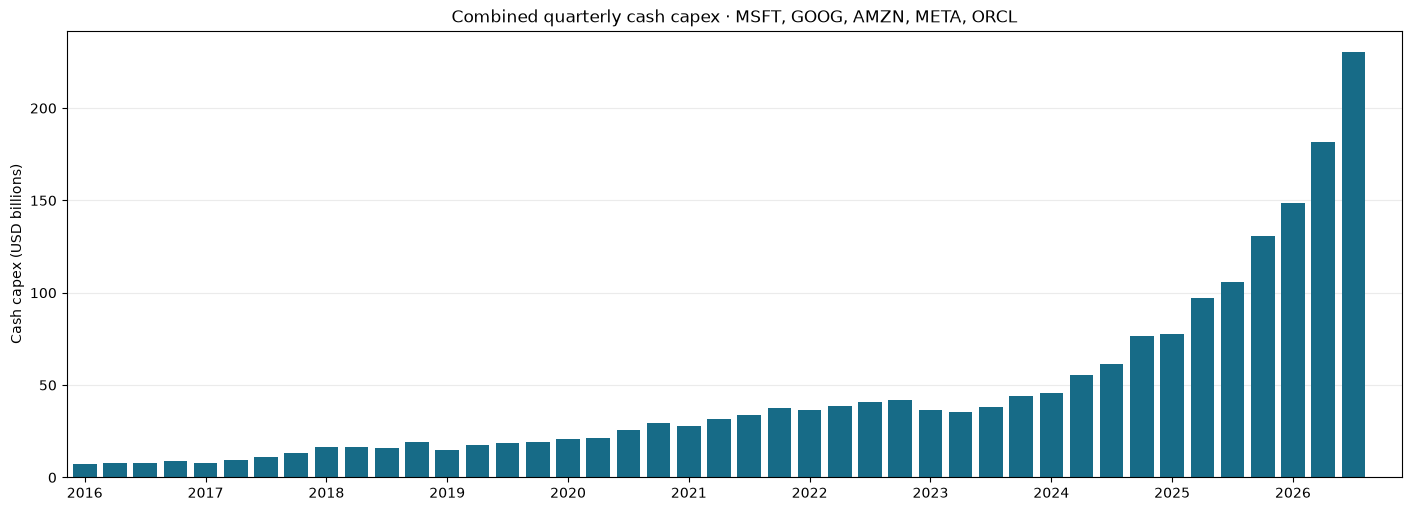

No five-company total for 2026Q4.


In [4]:
totals = capex_billions["Total"]
available = totals.notna()
if not available.any():
    raise ValueError("No quarter has capex data for all five companies.")

positions = range(len(totals))
year_ticks = [i for i, quarter in enumerate(totals.index) if quarter.quarter == 1]
fig, ax = plt.subplots(figsize=(14, 5), layout="constrained")
ax.bar(
    [i for i in positions if available.iloc[i]],
    totals[available],
    width=0.78,
    color="#176b87",
)
ax.set(
    title="Combined quarterly cash capex · MSFT, GOOG, AMZN, META, ORCL",
    ylabel="Cash capex (USD billions)",
    xlim=(-0.6, len(totals) - 0.4),
    ylim=(0, None),
)
ax.set_xticks(year_ticks, [str(totals.index[i].year) for i in year_ticks])
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
plt.show()

if not available.all():
    print("No five-company total for " + ", ".join(map(str, totals.index[~available])) + ".")


## Export the chart data

Run this cell from the repository to refresh `src/data/quarterly-capex.json`, which the website imports at build time. Each record contains a calendar quarter and its five-company total in billions of US dollars. Missing totals are stored as JSON `null`.

In [ ]:
import json
from pathlib import Path

cwd = Path.cwd()
repo_root = next(
    (path for path in (cwd, *cwd.parents) if (path / "src/components/AssignmentOne.jsx").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Run the notebook from the repository or one of its subdirectories.")

export_path = repo_root / "src/data/quarterly-capex.json"
export_path.parent.mkdir(parents=True, exist_ok=True)
records = [
    {"quarter": str(quarter), "totalUsdBillions": None if pd.isna(value) else round(float(value), 6)}
    for quarter, value in capex_billions["Total"].items()
]
export_path.write_text(json.dumps(records, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(f"Wrote {len(records)} quarters to {export_path.relative_to(repo_root)}")
